# Un modelo para el crecimiento de cucarachas

Modelamos una colonia de cucarachas con dos variables: $E(t)$, el número de huevos, y $A(t)$, el número de adultas. Los parámetros del enunciado son

| Parámetro | Descripción | Valor | Unidad |
|---|---|---|---|
| $b_A$ | puesta de huevos | 0.33 | por cucaracha por día |
| $g$ | maduración de huevos | 0.33 | por huevo por día |
| $d_A$ | muerte de adultas | 1/21 | por cucaracha por día |

(La maduración $g$ es una tasa por huevo: en promedio un huevo tarda $1/g \approx 3$ días en convertirse en adulta, y una adulta vive en promedio $1/d_A = 21$ días.)

**Contenido**

1. Crecimiento sin límites: equilibrios, estabilidad y retrato fase.
2. Adimensionalización.
3. Capacidad de carga: el nuevo equilibrio y su estabilidad.
4. Matar tres cucarachas al día: ¿se acaba la plaga?
5. ¿Cuántas hay que matar para extinguirla?

In [1]:
# ============================================================
# Bibliotecas y parámetros
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp   # integrador numérico de EDOs

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})

b_A = 0.33      # huevos puestos por adulta por día
g = 0.33        # tasa de maduración de huevos (por día)
d_A = 1 / 21    # tasa de muerte de adultas (por día)
k = 10_000      # capacidad de carga de un departamento (secciones 3-5)

## 1. Crecimiento sin limitaciones

$$
\frac{dE}{dt} = -gE + b_A A, \qquad \frac{dA}{dt} = gE - d_A A .
$$

Es un sistema **lineal**, $\dot{\mathbf{x}} = J\mathbf{x}$ con $\mathbf{x} = (E, A)$ y

$$
J = \begin{pmatrix} -g & b_A \\ g & -d_A \end{pmatrix}.
$$

**Equilibrios.** Resolvemos $J\mathbf{x} = 0$. Como $\det J = g d_A - g b_A = g(d_A - b_A) \neq 0$, la única solución es $(E, A) = (0, 0)$: la colonia o no existe o está cambiando.

**Estabilidad.** Los valores propios de $J$ son

$$
\lambda_{\pm} = \frac{\operatorname{tr} J \pm \sqrt{(\operatorname{tr} J)^2 - 4\det J}}{2},
\qquad \operatorname{tr} J = -(g + d_A),\quad \det J = g(d_A - b_A).
$$

Si $b_A > d_A$ (cada adulta pone huevos más rápido de lo que muere), $\det J < 0$ y los valores propios son reales y de signo contrario: el origen es un **punto silla**, inestable. Con los valores del enunciado $b_A = 0.33 > d_A \approx 0.048$, así que **cualquier colonia, por pequeña que sea, crece exponencialmente** con tasa $\lambda_+$.

In [2]:
J = np.array([[-g, b_A],
              [g, -d_A]])
valores, vectores = np.linalg.eig(J)   # valores y vectores propios (columnas)
# Los valores propios son reales (det J < 0); numpy puede regresarlos con tipo
# complejo y parte imaginaria cero, así que nos quedamos con la parte real.
valores, vectores = valores.real, vectores.real
orden = np.argsort(valores)[::-1]       # primero el positivo
valores, vectores = valores[orden], vectores[:, orden]
# Normalizamos cada vector propio para que su componente más grande valga +1.
vectores = vectores / vectores[np.abs(vectores).argmax(axis=0), [0, 1]]

print(f"traza = {np.trace(J):.4f},  determinante = {np.linalg.det(J):.4f}")
for lam, v in zip(valores, vectores.T):
    print(f"lambda = {lam:+.4f} por día, vector propio (E, A) = {np.round(v, 3)}")
lam_mas = valores[0]
print(f"\nTiempo de duplicación de la colonia: ln 2 / lambda+ = {np.log(2) / lam_mas:.1f} días")
print(f"En un año la colonia se multiplicaría por e^(365 lambda+) ≈ {np.exp(365 * lam_mas):.2e}")

traza = -0.3776,  determinante = -0.0932
lambda = +0.1701 por día, vector propio (E, A) = [0.66 1.  ]
lambda = -0.5477 por día, vector propio (E, A) = [ 1.   -0.66]

Tiempo de duplicación de la colonia: ln 2 / lambda+ = 4.1 días
En un año la colonia se multiplicaría por e^(365 lambda+) ≈ 9.29e+26


El vector propio de $\lambda_+$ tiene componentes positivas (con estos valores, unos 2 huevos por cada 3 adultas): es la **estructura de edades estable** a la que converge cualquier colonia mientras crece. El otro vector propio tiene componentes de signo contrario y no es biológicamente alcanzable como estado, pero sí indica la dirección en la que se corrigen los desequilibrios entre huevos y adultas.

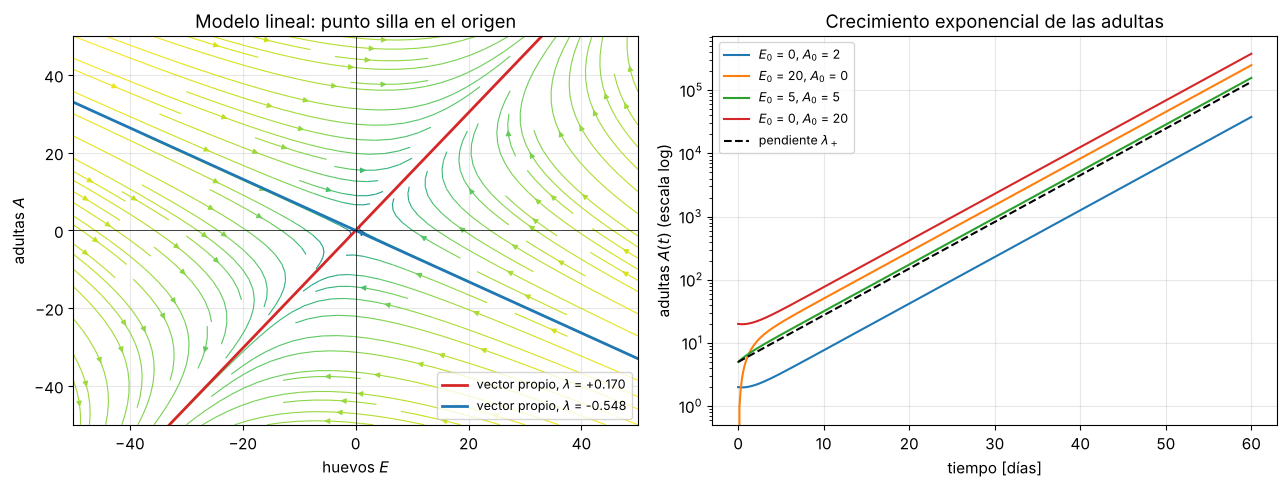

In [3]:
def retrato_fase(ax, campo, xlim, ylim, titulo, densidad=1.2):
    """
    Dibuja el campo de direcciones de dX/dt = campo(E, A) con líneas de flujo
    (streamplot) coloreadas por la rapidez del cambio.
    """
    E, A = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    dE, dA = campo(E, A)
    rapidez = np.hypot(dE, dA)
    ax.streamplot(E, A, dE, dA, color=np.log10(rapidez + 1e-12), cmap="viridis",
                  density=densidad, linewidth=0.8, arrowsize=0.8)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("huevos $E$")
    ax.set_ylabel("adultas $A$")
    ax.set_title(titulo)


def campo_lineal(E, A):
    """Lado derecho del modelo sin limitaciones."""
    return -g * E + b_A * A, g * E - d_A * A


fig, axs = plt.subplots(1, 2, figsize=(13, 5))
retrato_fase(axs[0], campo_lineal, (-50, 50), (-50, 50), "Modelo lineal: punto silla en el origen")
for lam, v, c in zip(valores, vectores.T, ["C3", "C0"]):
    s = np.linspace(-80, 80, 2)
    axs[0].plot(s * v[0], s * v[1], c, lw=2, label=rf"vector propio, $\lambda$ = {lam:+.3f}")
axs[0].axhline(0, color="k", lw=0.5)
axs[0].axvline(0, color="k", lw=0.5)
axs[0].legend(loc="lower right", fontsize=9)

# Trayectorias desde distintas condiciones iniciales (solo tienen sentido E, A >= 0).
t_eval = np.linspace(0, 60, 400)
for E0, A0 in [(0, 2), (20, 0), (5, 5), (0, 20)]:
    sol = solve_ivp(lambda t, y: campo_lineal(*y), (0, 60), [E0, A0], t_eval=t_eval)
    axs[1].semilogy(sol.t, sol.y[1], label=f"$E_0$ = {E0}, $A_0$ = {A0}")
axs[1].semilogy(t_eval, 5 * np.exp(lam_mas * t_eval), "k--", label=r"pendiente $\lambda_+$")
axs[1].set_xlabel("tiempo [días]")
axs[1].set_ylabel("adultas $A(t)$ (escala log)")
axs[1].set_title("Crecimiento exponencial de las adultas")
axs[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 2. Adimensionalización

Queremos reescribir el sistema con variables sin unidades y con el menor número posible de parámetros. Elegimos escalas para el tiempo y las poblaciones:

$$
\tau = g\,t, \qquad e = \frac{E}{N_0}, \qquad a = \frac{A}{N_0},
$$

donde $1/g$ (el tiempo medio de maduración) es la escala de tiempo y $N_0$ una escala de población. Sustituyendo, $\dfrac{dE}{dt} = g N_0 \dfrac{de}{d\tau}$, y dividiendo entre $gN_0$:

$$
\frac{de}{d\tau} = -e + \beta\,a, \qquad \frac{da}{d\tau} = e - \delta\,a,
\qquad \beta = \frac{b_A}{g},\quad \delta = \frac{d_A}{g}.
$$

Pasamos de tres parámetros ($b_A$, $g$, $d_A$) a dos ($\beta$, $\delta$), y los dos tienen significado:

* $\beta$: huevos que pone una adulta durante el tiempo que tarda un huevo en madurar.
* $\delta$: fracción de adultas que muere en ese mismo tiempo; $1/\delta$ es la vida media adulta medida en "tiempos de maduración".

Como el sistema lineal no tiene una escala natural de población, $N_0$ es arbitraria (por ejemplo, $N_0 = 1$). La colonia crece si $\beta > \delta$, es decir, si $b_A > d_A$. Con los datos: $\beta = 1$ y $\delta = 1/(21\cdot 0.33) \approx 0.144$.

**Con capacidad de carga (sección 3)** la escala natural es $N_0 = k$:

$$
\frac{de}{d\tau} = -e + \beta\,a, \qquad
\frac{da}{d\tau} = (1 - a)\,e - \delta\,(1 + a)\,a ,
$$

así que la dinámica depende solo de $\beta$ y $\delta$; $k$ únicamente fija el tamaño. Con la matanza de la sección 4 aparece un tercer parámetro adimensional, $\eta = h/(g k)$ (cucarachas matadas por tiempo de maduración, en unidades de la capacidad de carga).

In [4]:
beta = b_A / g
delta = d_A / g
print(f"beta  = b_A / g = {beta:.4f}")
print(f"delta = d_A / g = {delta:.4f}")
print(f"Valores propios adimensionales: {np.round(np.linalg.eigvals([[-1, beta], [1, -delta]]).real, 4)}")
print(f"(son los de J divididos entre g: {np.round(valores / g, 4)})")

beta  = b_A / g = 1.0000
delta = d_A / g = 0.1443
Valores propios adimensionales: [-1.6598  0.5155]
(son los de J divididos entre g: [ 0.5155 -1.6598])


## 3. Capacidad de carga

$$
\frac{dE}{dt} = -gE + b_A A, \qquad
\frac{dA}{dt} = \left(1 - \frac{A}{k}\right) gE - \left(1 + \frac{A}{k}\right) d_A A .
$$

Cuando hay muchas adultas, menos huevos logran convertirse en adultas (factor $1 - A/k$) y la mortalidad aumenta (factor $1 + A/k$).

**Equilibrios.** De $dE/dt = 0$: $E = \dfrac{b_A}{g}A$. Sustituyendo en $dA/dt = 0$:

$$
A\left[\left(1 - \frac{A}{k}\right) b_A - \left(1 + \frac{A}{k}\right) d_A\right] = 0
\;\Longrightarrow\;
A = 0 \quad\text{o}\quad A^{\ast} = k\,\frac{b_A - d_A}{b_A + d_A}, \quad E^{\ast} = \frac{b_A}{g}A^{\ast}.
$$

El equilibrio positivo existe si $b_A > d_A$, la misma condición de crecimiento de antes.

**Jacobiano.**

$$
J(E, A) = \begin{pmatrix} -g & b_A \\[2pt] g\left(1 - \dfrac{A}{k}\right) & -\dfrac{gE}{k} - d_A\left(1 + \dfrac{2A}{k}\right) \end{pmatrix}.
$$

En el origen coincide con el del modelo lineal: sigue siendo un **punto silla** (una colonia pequeña crece). En $(E^{\ast}, A^{\ast})$ lo evaluamos numéricamente.

In [5]:
def campo_k(E, A, h=0.0):
    """Modelo con capacidad de carga k y h cucarachas adultas matadas por día."""
    dE = -g * E + b_A * A
    dA = (1 - A / k) * g * E - (1 + A / k) * d_A * A - h
    return dE, dA


def jacobiano_k(E, A):
    """Jacobiano del modelo con capacidad de carga (no depende de h)."""
    return np.array([[-g, b_A],
                     [g * (1 - A / k), -g * E / k - d_A * (1 + 2 * A / k)]])


def clasificar(Jm):
    """Clasifica un equilibrio a partir de los valores propios de su jacobiano."""
    lam = np.linalg.eigvals(Jm)
    if np.all(np.abs(lam.imag) < 1e-12):
        lam = lam.real
        if np.all(lam < 0):
            tipo = "nodo estable"
        elif np.all(lam > 0):
            tipo = "nodo inestable"
        else:
            tipo = "punto silla (inestable)"
    else:
        tipo = "foco estable" if lam[0].real < 0 else "foco inestable"
    return lam, tipo


A_est = k * (b_A - d_A) / (b_A + d_A)
E_est = b_A / g * A_est
for nombre, (E0, A0) in [("origen", (0, 0)), ("(E*, A*)", (E_est, A_est))]:
    lam, tipo = clasificar(jacobiano_k(E0, A0))
    print(f"{nombre:9s}: E = {E0:7.1f}, A = {A0:7.1f}, valores propios = {np.round(lam, 4)} -> {tipo}")

origen   : E =     0.0, A =     0.0, valores propios = [-0.5477  0.1701] -> punto silla (inestable)
(E*, A*) : E =  7477.9, A =  7477.9, valores propios = [-0.1811 -0.5145] -> nodo estable


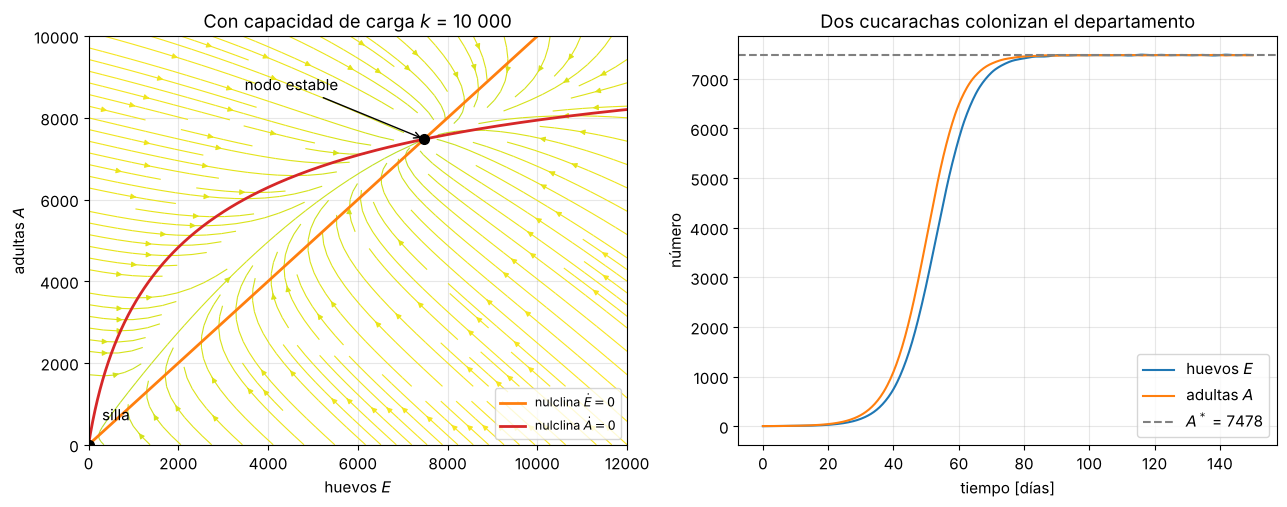

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
retrato_fase(axs[0], campo_k, (0, 12000), (0, 10000), "Con capacidad de carga $k$ = 10 000")
# Nulclinas: dE/dt = 0  ->  A = g E / b_A ;  dA/dt = 0  ->  E = (1 + A/k) d_A A / ((1 - A/k) g)
A_n = np.linspace(0, 0.999 * k, 400)
E_n = np.linspace(0, 12000, 2)
axs[0].plot(E_n, g * E_n / b_A, "C1", lw=2, label="nulclina $\\dot E = 0$")
axs[0].plot((1 + A_n / k) * d_A * A_n / ((1 - A_n / k) * g), A_n, "C3", lw=2, label="nulclina $\\dot A = 0$")
axs[0].plot([0, E_est], [0, A_est], "ko", ms=7)
axs[0].annotate("silla", (0, 0), (300, 600))
axs[0].annotate("nodo estable", (E_est, A_est), (E_est - 4000, A_est + 1200),
                arrowprops=dict(arrowstyle="->"))
axs[0].legend(loc="lower right", fontsize=9)

# Evolución temporal desde una infestación pequeña.
sol = solve_ivp(lambda t, y: campo_k(*y), (0, 150), [0, 2], t_eval=np.linspace(0, 150, 500))
axs[1].plot(sol.t, sol.y[0], label="huevos $E$")
axs[1].plot(sol.t, sol.y[1], label="adultas $A$")
axs[1].axhline(A_est, color="gray", ls="--", label=f"$A^*$ = {A_est:.0f}")
axs[1].set_xlabel("tiempo [días]")
axs[1].set_ylabel("número")
axs[1].set_title("Dos cucarachas colonizan el departamento")
axs[1].legend()
plt.tight_layout()
plt.show()

El equilibrio positivo es un **nodo estable**: la colonia crece casi exponencialmente al inicio, luego se frena y se estabiliza en unas 7 500 adultas y otros tantos huevos. Además, la región $A \le k$ es invariante: si $A = k$, entonces $dA/dt = -2 d_A k < 0$, así que las trayectorias que empiezan con $A \le k$ nunca superan la capacidad de carga.

## 4. Matar tres cucarachas adultas al día

$$
\frac{dA}{dt} = \left(1 - \frac{A}{k}\right) gE - \left(1 + \frac{A}{k}\right) d_A A - h, \qquad h = 3 .
$$

**Equilibrios.** Sigue valiendo $E = \dfrac{b_A}{g}A$, y ahora $dA/dt = 0$ da una ecuación cuadrática:

$$
\frac{b_A + d_A}{k}A^2 - (b_A - d_A)A + h = 0
\quad\Longrightarrow\quad
A_{\pm} = \frac{k}{2}\,\frac{(b_A - d_A) \pm \sqrt{(b_A - d_A)^2 - 4h(b_A + d_A)/k}}{b_A + d_A}.
$$

(El origen ya no es equilibrio: con $A = 0$ seguiríamos "matando" cucarachas inexistentes. El modelo solo tiene sentido mientras $A > 0$; cuando $A$ llega a cero, la plaga se extinguió.)

In [7]:
def equilibrios_con_matanza(h):
    """Regresa (A_-, A_+) para una matanza de h adultas por día (o None si no existen)."""
    a2 = (b_A + d_A) / k
    a1 = -(b_A - d_A)
    disc = a1**2 - 4 * a2 * h
    if disc < 0:
        return None
    return (-a1 - np.sqrt(disc)) / (2 * a2), (-a1 + np.sqrt(disc)) / (2 * a2)


h = 3
A_menos, A_mas = equilibrios_con_matanza(h)
for nombre, A_q in [("A-", A_menos), ("A+", A_mas)]:
    E_q = b_A / g * A_q
    lam, tipo = clasificar(jacobiano_k(E_q, A_q))
    print(f"{nombre}: E = {E_q:8.2f}, A = {A_q:8.2f}, valores propios = {np.round(lam, 4)} -> {tipo}")
print(f"\nSin matanza A* = {A_est:.1f}; con h = 3 el equilibrio grande baja a {A_mas:.1f}"
      f" (una diferencia de {A_est - A_mas:.1f} adultas).")

A-: E =    10.64, A =    10.64, valores propios = [-0.5477  0.1696] -> punto silla (inestable)
A+: E =  7467.29, A =  7467.29, valores propios = [-0.1806 -0.5146] -> nodo estable

Sin matanza A* = 7477.9; con h = 3 el equilibrio grande baja a 7467.3 (una diferencia de 10.6 adultas).


Hay dos equilibrios: uno grande, $A_+$, que es un **nodo estable** y apenas difiere del de la sección 3, y uno pequeño, $A_-$, que es un **punto silla**. La variedad estable de la silla (la *separatriz*) divide el plano en dos regiones: por debajo de ella la plaga se extingue; por encima, la colonia se recupera y llega a $A_+$. La calculamos integrando el sistema **hacia atrás en el tiempo** desde puntos muy cercanos a la silla, en la dirección de su vector propio estable.

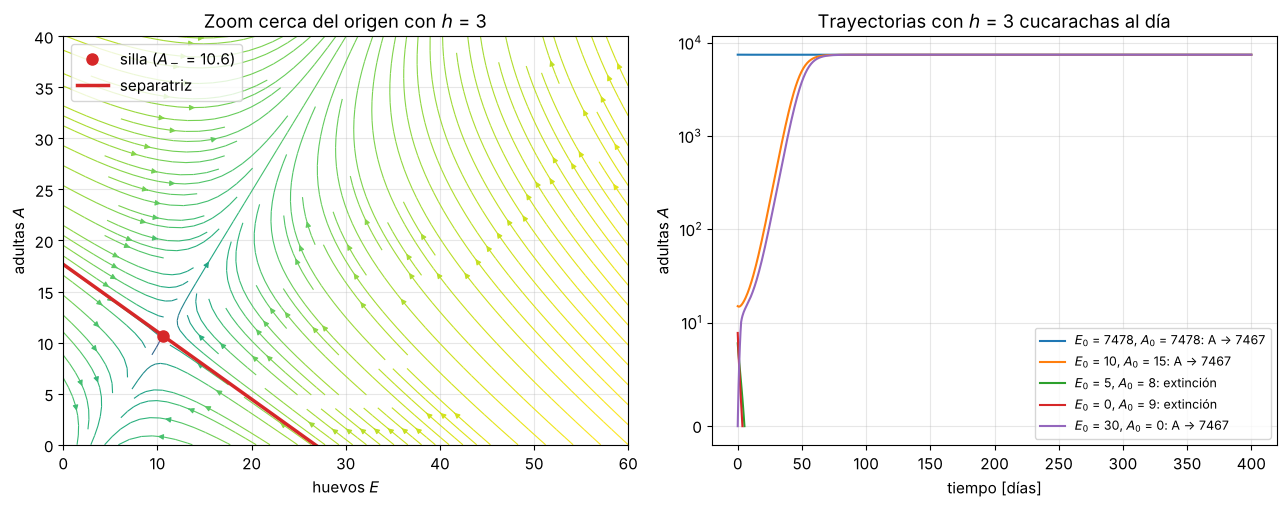

In [8]:
def evento_extincion(t, y, h):
    """Detiene la integración cuando las adultas llegan a cero."""
    return y[1]
evento_extincion.terminal = True
evento_extincion.direction = -1


def simular(E0, A0, h, t_max=400):
    """Integra el modelo con matanza h hasta t_max o hasta que A = 0."""
    return solve_ivp(lambda t, y, h: campo_k(*y, h=h), (0, t_max), [E0, A0], args=(h,),
                     events=evento_extincion, max_step=0.5, dense_output=True)


def separatriz(h, longitud=60):
    """Variedad estable de la silla A_-: integración hacia atrás desde la silla."""
    A_s = equilibrios_con_matanza(h)[0]
    E_s = b_A / g * A_s
    lam, vec = np.linalg.eig(jacobiano_k(E_s, A_s))
    v = vec[:, np.argmin(lam.real)].real            # dirección estable
    ramas = []
    for signo in [+1, -1]:
        y0 = np.array([E_s, A_s]) + signo * 1e-3 * v
        # Hacia atrás en el tiempo la solución se aleja y puede explotar; la
        # detenemos en cuanto sale de la ventana que nos interesa.
        fuera = lambda t, y: 200 - max(abs(y[0]), abs(y[1]))
        fuera.terminal = True
        sol = solve_ivp(lambda t, y: [-d for d in campo_k(*y, h=h)], (0, longitud), y0,
                        max_step=0.05, events=fuera)
        ramas.append(sol.y)
    return ramas, (E_s, A_s)


fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
retrato_fase(axs[0], lambda E, A: campo_k(E, A, h=3), (0, 60), (0, 40),
             "Zoom cerca del origen con $h$ = 3", densidad=1.4)
ramas, (E_s, A_s) = separatriz(3)
for r in ramas:
    axs[0].plot(r[0], r[1], "C3", lw=2.5)
axs[0].plot(E_s, A_s, "C3o", ms=8, label=f"silla ($A_-$ = {A_s:.1f})")
axs[0].plot([], [], "C3", lw=2.5, label="separatriz")
axs[0].legend(loc="upper left")

for (E0, A0) in [(E_est, A_est), (10, 15), (5, 8), (0, 9), (30, 0)]:
    sol = simular(E0, A0, h=3)
    fin = "extinción" if sol.status == 1 else f"A → {sol.y[1, -1]:.0f}"
    axs[1].plot(sol.t, sol.y[1], label=f"$E_0$ = {E0:.0f}, $A_0$ = {A0:.0f}: {fin}")
axs[1].set_yscale("symlog", linthresh=10)
axs[1].set_xlabel("tiempo [días]")
axs[1].set_ylabel("adultas $A$")
axs[1].set_title("Trayectorias con $h$ = 3 cucarachas al día")
axs[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

**Respuesta a la pregunta 4: no.** Si la plaga ya está establecida (miles de cucarachas), matar 3 al día solo baja el equilibrio en unas 10 adultas. Matar a ritmo constante solo funciona si la colonia es **muy pequeña**, por debajo de la separatriz (del orden de una decena de adultas y huevos). Es la misma lógica de la pesca con cuota fija: una extracción constante es irrelevante para una población grande y letal para una pequeña.

## 5. ¿Cuántas hay que matar al día para extinguir la plaga?

Los dos equilibrios $A_{\pm}$ existen mientras el discriminante sea no negativo. Cuando $h$ crece, la silla y el nodo se acercan, chocan y desaparecen: es una **bifurcación silla-nodo**. A partir de ese valor no hay ningún equilibrio con $A>0$ y $dA/dt<0$ en todo el plano: **la plaga se extingue desde cualquier condición inicial**. La condición es

$$
h > h_c = \frac{k\,(b_A - d_A)^2}{4\,(b_A + d_A)} .
$$

h_c = 527.9 cucarachas adultas por día
En el punto de bifurcación A = 3739 (la mitad de A* sin matanza)


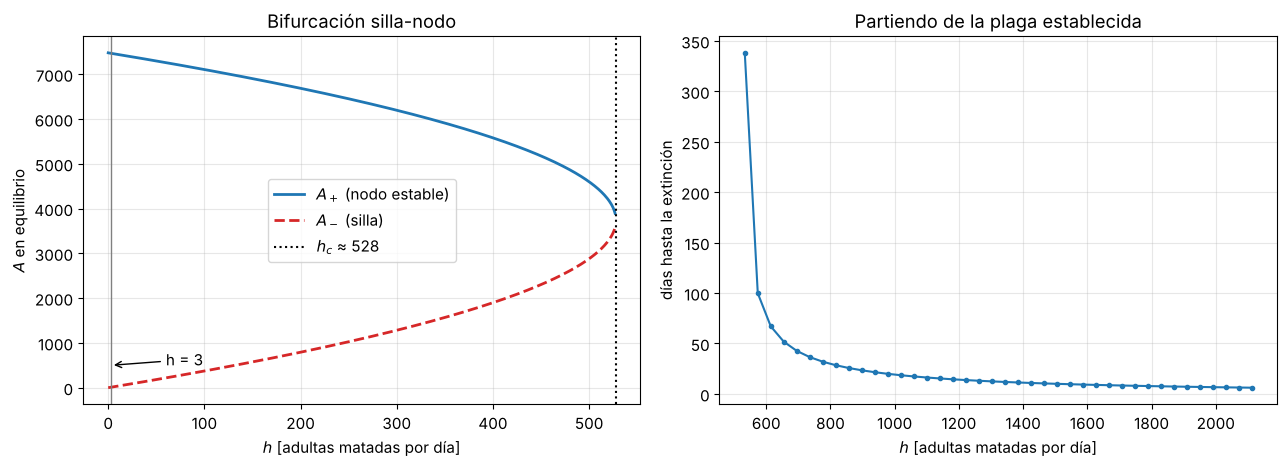

In [9]:
h_c = k * (b_A - d_A) ** 2 / (4 * (b_A + d_A))
print(f"h_c = {h_c:.1f} cucarachas adultas por día")
print(f"En el punto de bifurcación A = {k * (b_A - d_A) / (2 * (b_A + d_A)):.0f} (la mitad de A* sin matanza)")

# Diagrama de bifurcación: A_- y A_+ contra h.
hs = np.linspace(0, 1.15 * h_c, 600)
Am, Ap = [], []
for hq in hs:
    r = equilibrios_con_matanza(hq)
    Am.append(r[0] if r else np.nan)
    Ap.append(r[1] if r else np.nan)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].plot(hs, Ap, "C0", lw=2, label="$A_+$ (nodo estable)")
axs[0].plot(hs, Am, "C3--", lw=2, label="$A_-$ (silla)")
axs[0].axvline(h_c, color="k", ls=":", label=f"$h_c$ ≈ {h_c:.0f}")
axs[0].axvline(3, color="gray", lw=1)
axs[0].annotate("h = 3", (3, 500), (60, 500), arrowprops=dict(arrowstyle="->"))
axs[0].set_xlabel("$h$ [adultas matadas por día]")
axs[0].set_ylabel("$A$ en equilibrio")
axs[0].set_title("Bifurcación silla-nodo")
axs[0].legend()

# Tiempo de extinción desde la plaga establecida, para h > h_c.
h_vals = np.linspace(1.01 * h_c, 4 * h_c, 40)
t_ext = []
for hq in h_vals:
    sol = simular(E_est, A_est, hq, t_max=2000)
    t_ext.append(sol.t_events[0][0] if sol.status == 1 else np.nan)
axs[1].plot(h_vals, t_ext, "o-", ms=3)
axs[1].set_xlabel("$h$ [adultas matadas por día]")
axs[1].set_ylabel("días hasta la extinción")
axs[1].set_title("Partiendo de la plaga establecida")
plt.tight_layout()
plt.show()

Cerca de $h_c$ el tiempo de extinción se dispara: la trayectoria pasa muchísimo tiempo cerca del lugar donde los equilibrios desaparecieron (el "fantasma" de la bifurcación silla-nodo). Matar apenas por encima de 528 al día funciona, pero tarda mucho.

### Una estrategia más inteligente: un golpe fuerte y luego mantenimiento

La sección 4 sugiere otra estrategia: no hace falta matar 528 cucarachas al día para siempre. Basta con **llevar la colonia por debajo de la separatriz** con una fumigación intensa y después mantener una matanza pequeña. ¿Qué fracción hay que eliminar de golpe? Supongamos que la fumigación elimina la misma fracción de huevos y de adultas, y que después se matan 3 adultas al día.

In [10]:
def se_extingue(fraccion_sobreviviente, h=3, t_max=3000):
    """¿Se extingue la plaga si sobrevive esa fracción y luego se matan h al día?"""
    sol = simular(fraccion_sobreviviente * E_est, fraccion_sobreviviente * A_est, h, t_max)
    return sol.status == 1


# Bisección sobre la fracción sobreviviente.
lo, hi = 0.0, 0.01   # con 0 se extingue, con 1 % sobreviviente (≈ 75 adultas) no
for _ in range(40):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if se_extingue(mid) else (lo, mid)
print(f"Con h = 3 hay que dejar menos del {100 * lo:.3f} % de la colonia:"
      f" a lo sumo ≈ {lo * A_est:.1f} adultas y {lo * E_est:.1f} huevos.")

# Alternativa: matar una FRACCIÓN fija de adultas por día (q A en vez de h).
print(f"\nSi en lugar de un número fijo se mata una fracción q de las adultas por día,")
print(f"el término es -q A y la plaga se extingue si q > b_A - d_A = {b_A - d_A:.3f}"
      f" (≈ {100 * (b_A - d_A):.0f} % de las adultas cada día).")

Con h = 3 hay que dejar menos del 0.142 % de la colonia: a lo sumo ≈ 10.6 adultas y 10.6 huevos.

Si en lugar de un número fijo se mata una fracción q de las adultas por día,
el término es -q A y la plaga se extingue si q > b_A - d_A = 0.282 (≈ 28 % de las adultas cada día).


**Condiciones para la extinción, en resumen:**

1. **Matanza constante y suficiente:** $h > h_c = \dfrac{k(b_A - d_A)^2}{4(b_A + d_A)} \approx 528$ adultas por día. Garantiza la extinción desde cualquier estado.
2. **Matanza constante pequeña ($h < h_c$) y colonia pequeña:** la plaga se extingue si el estado inicial está por debajo de la separatriz de la silla $A_-$. Con $h = 3$ eso significa dejar apenas una decena de cucarachas: una fumigación que elimine alrededor del 99.86 % de la colonia, seguida de mantenimiento.
3. **Matanza proporcional** (por ejemplo, trampas cuya captura crece con la población): basta con que la tasa de captura por adulta supere $b_A - d_A$. Notablemente, esta condición **no depende de** $k$.

Una observación final: el modelo es determinista y continuo. Cuando quedan pocas cucarachas, la aleatoriedad (qué individuo muere, si los huevos eclosionan) importa mucho y la extinción puede ocurrir antes o no ocurrir; un modelo estocástico sería más apropiado en esa región.

**Referencia:** Albert, H., Buchmann, A., Ohm, L., Radunskaya, A., Swanson, E. (2016). Controlling a Cockroach Infestation. En *Advances in the Mathematical Sciences*, AWM Series vol. 6, Springer.